# Microproyecto 1 — Generación de bocetos con redes recurrentes

**Curso:** Modelos Avanzados de Procesamiento de Lenguaje Natural  
**Estudiante:** Juan David Villalba  
**Categoría seleccionada:** `apple`  
**Fecha:** 15 de octubre de 2026  

## Resumen del proyecto

En este notebook se implementa y entrena desde cero un modelo de red neuronal recurrente en PyTorch para generar bocetos de la categoría `apple` del dataset Quick, Draw!. El modelo recibe una secuencia de movimientos del lápiz y predice el siguiente movimiento: los desplazamientos relativos en los ejes \(x\) e \(y\), y el estado del lápiz.

El modelo utiliza una arquitectura LSTM y dos cabezas de salida: una para regresión de los desplazamientos y otra para clasificación del estado del lápiz. La función de pérdida combina una componente de regresión y una componente de clasificación.

## 1. Portada e introducción

### Objetivo

Implementar y entrenar desde cero, en PyTorch, un modelo recurrente
capaz de generar nuevos bocetos de la categoría `apple` del dataset
Quick, Draw!, mediante la predicción del siguiente movimiento del lápiz.

### Diagrama de la arquitectura
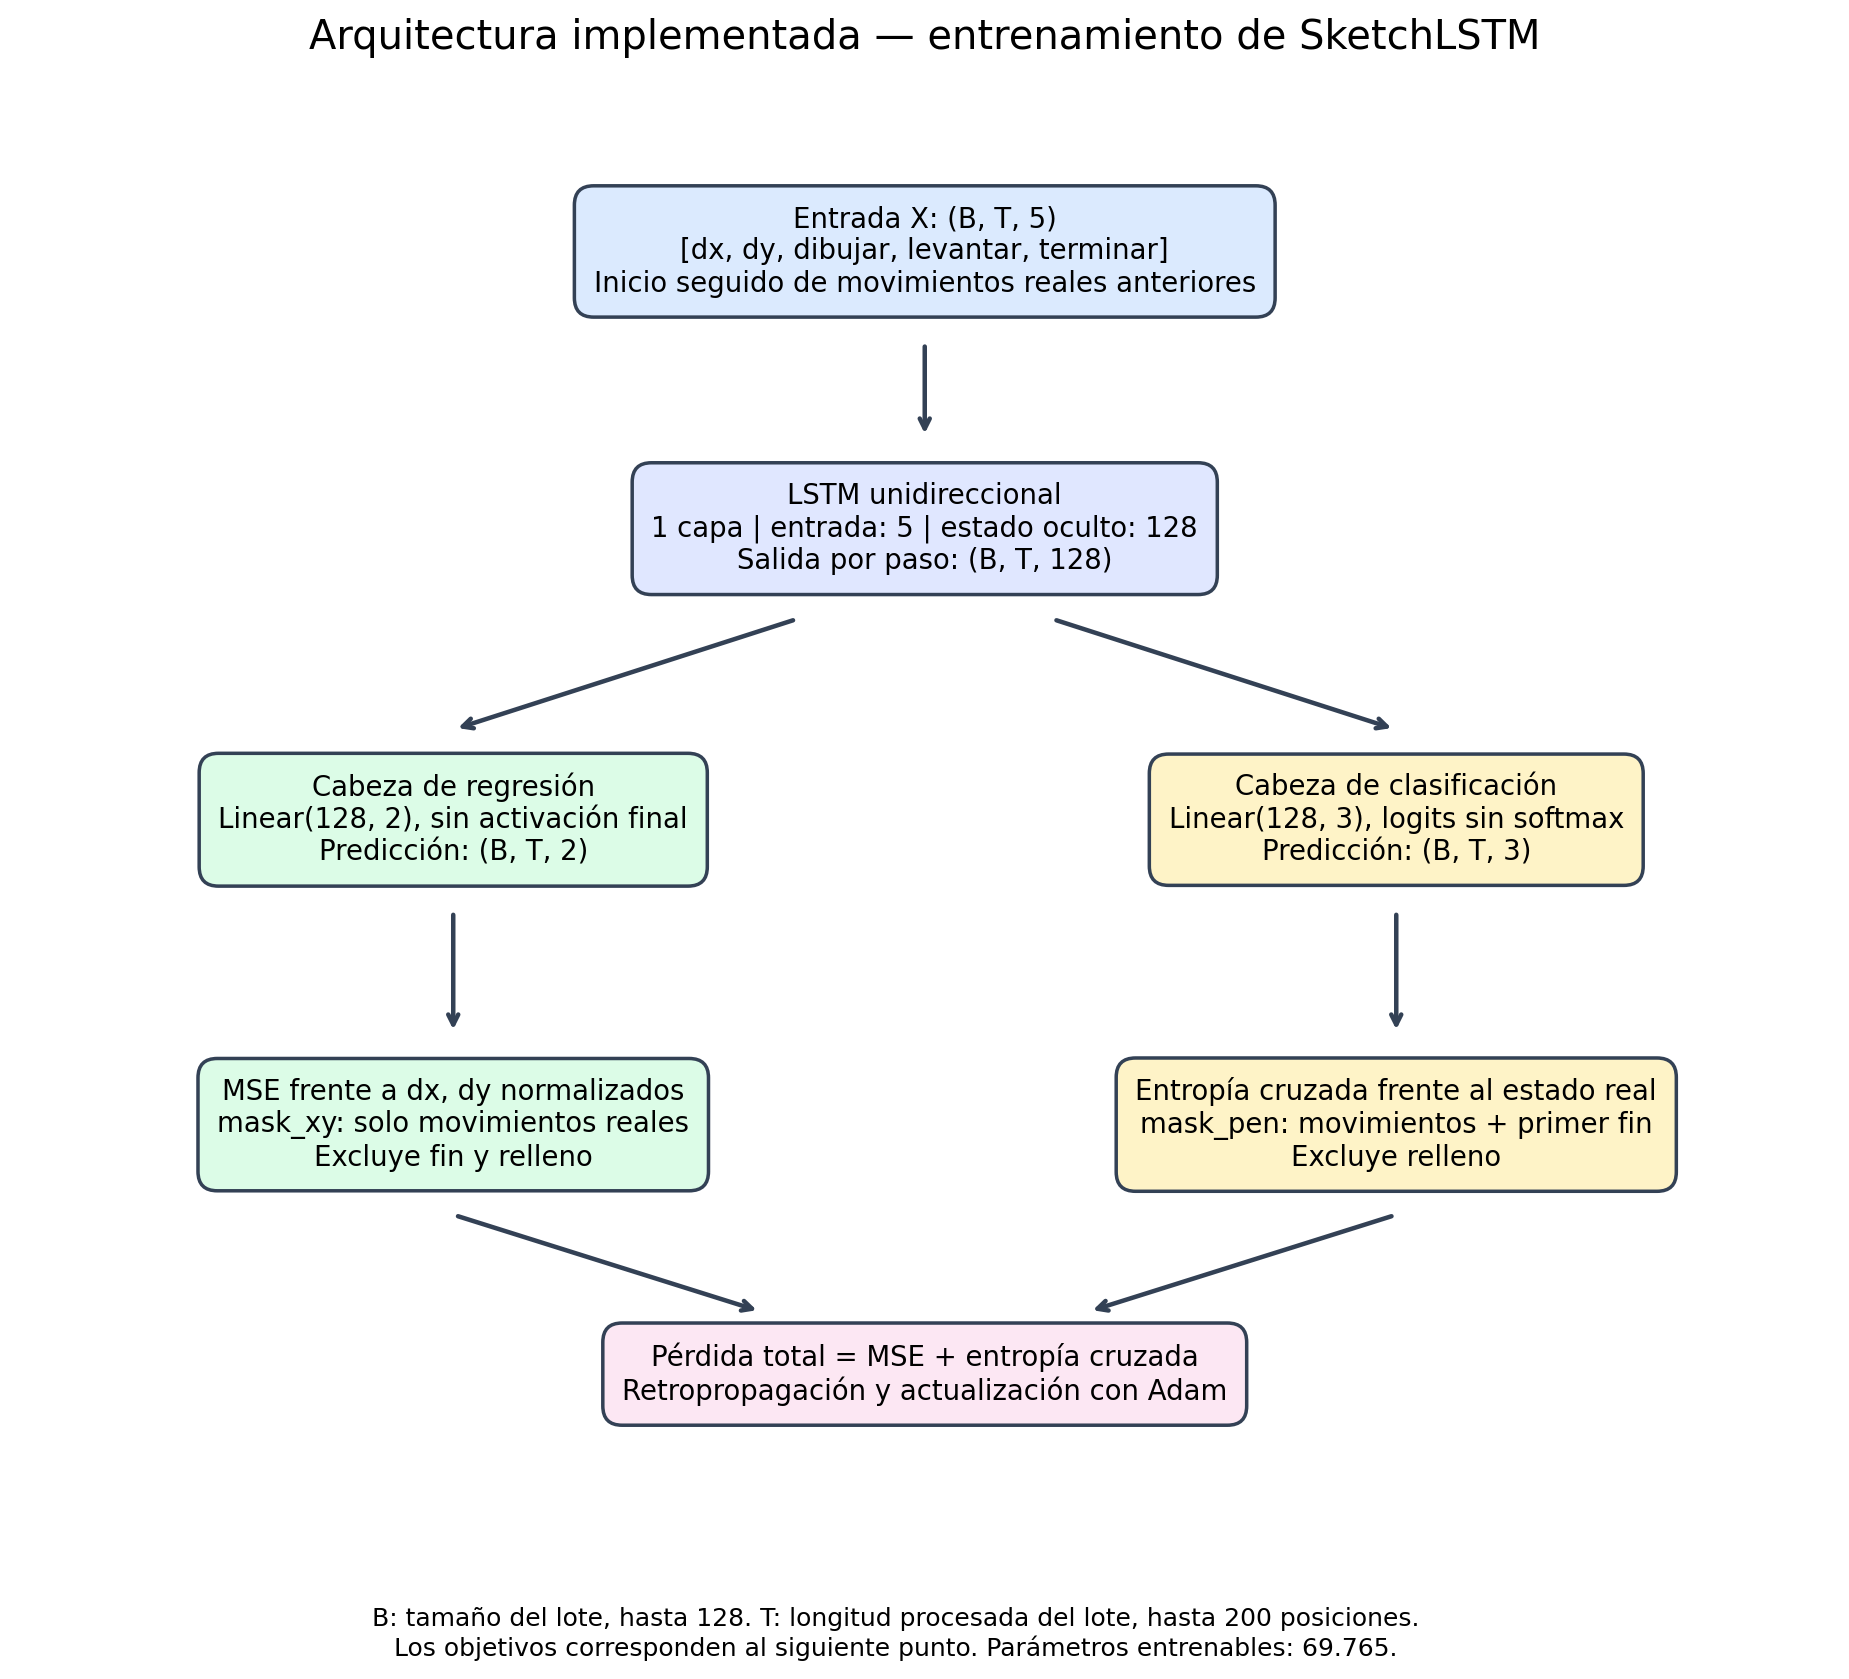

### Representación de las entradas

Cada posición se representa mediante cinco valores:

[delta_x, delta_y, dibujar, levantar, terminar]

Los desplazamientos se normalizan dividiéndolos por sus respectivas
desviaciones estándar, calculadas exclusivamente con entrenamiento:
27.672750 para delta_x y 32.689018 para delta_y.

Los tres últimos valores codifican el estado del lápiz mediante un vector
one-hot. Aunque la entrada tiene cinco componentes numéricas, representa
tres características conceptuales: dos desplazamientos y un estado
categórico con tres posibilidades.

Se conservan hasta 199 movimientos y se añade una señal de fin, sin
superar 200 posiciones. Las secuencias más cortas se completan con relleno,
que se identifica mediante máscaras.

### Arquitectura implementada

El modelo contiene una LSTM unidireccional de una capa, con entrada de
dimensión 5 y estado oculto de dimensión 128. La representación de cada
paso se utiliza en dos cabezas de salida:

1. Una capa Linear(128, 2), sin activación final, predice los dos
   desplazamientos normalizados. No se restringe su signo porque el
   lápiz puede desplazarse en ambas direcciones de cada eje.

2. Una capa Linear(128, 3) produce logits para los estados dibujar,
   levantar y terminar. Durante el entrenamiento se entregan directamente
   a la entropía cruzada, sin aplicar softmax previamente.

La implementación tiene 69.765 parámetros entrenables. Los parámetros
se inicializan sin utilizar pesos preentrenados.

### Contexto y predicción del siguiente punto

Las entradas y los objetivos están desplazados una posición. Una señal
de inicio permite predecir el primer movimiento; después, cada movimiento
real se utiliza para predecir el siguiente. El último movimiento tiene
como objetivo la señal de fin.

La LSTM acumula información de los puntos anteriores mediante su estado
recurrente. Al ser unidireccional, no utiliza puntos futuros para predecir
el siguiente punto.

Durante entrenamiento y evaluación a un paso se utilizan movimientos
reales anteriores. Durante generación se realimentan los movimientos
predichos y se conserva el estado recurrente entre pasos.

### Función de pérdida y enmascaramiento

La pérdida total es la suma, con pesos unitarios, de:

- MSE sobre los movimientos reales y sus dos coordenadas normalizadas.
- Entropía cruzada sobre los estados de los movimientos y la primera
  señal de fin de cada dibujo.

La máscara de coordenadas excluye tanto la señal de fin como el relleno.
La máscara de estados incluye la primera señal de fin, pero excluye el
relleno posterior. Así, la red aprende a terminar sin utilizar las
repeticiones de relleno como ejemplos adicionales.

### Justificación de la selección

La arquitectura recurrente se eligió porque un boceto es una secuencia
ordenada de movimientos cuyo siguiente punto depende del contexto
anterior. Se utilizó una LSTM para mantener una representación recurrente
de ese contexto.

Las dos cabezas permiten compartir la representación secuencial y
resolver simultáneamente una tarea de regresión y una de clasificación,
de acuerdo con la naturaleza de las salidas.

Se eligió una sola capa y 128 unidades como configuración inicial
compacta para desarrollar y verificar el proyecto con los recursos
disponibles. No se afirma que esta configuración sea óptima, ya que no
se realizó una comparación sistemática entre arquitecturas.

La solución es un predictor recurrente con regresión directa de
coordenadas; no reproduce la arquitectura probabilística completa
del Sketch-RNN original.

## 2. Librerías

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import torch

from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

import time

import csv
from sklearn.metrics import f1_score, classification_report, confusion_matrix

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 3. Lectura del dataset y exploración

In [2]:
CATEGORY = "apple"

DATA_DIR = Path("/content/datos")
DATA_DIR.mkdir(parents=True, exist_ok=True)

dataset_path = DATA_DIR / f"{CATEGORY}.npz"
dataset_url = (
    "https://storage.googleapis.com/"
    f"quickdraw_dataset/sketchrnn/{CATEGORY}.npz"
)

if not dataset_path.exists():
    print(f"Descargando {CATEGORY}.npz...")
    urllib.request.urlretrieve(dataset_url, dataset_path)
else:
    print("El archivo ya existe; no se descargará nuevamente.")

with np.load(
    dataset_path,
    encoding="latin1",
    allow_pickle=True
) as dataset:
    train_original = dataset["train"]
    valid_original = dataset["valid"]
    test_original = dataset["test"]

print("\nArchivo cargado correctamente.")
print("Categoría:", CATEGORY)
print("Tamaño del archivo:", dataset_path.stat().st_size, "bytes")
print("Bocetos originales de entrenamiento:", len(train_original))
print("Bocetos originales de validación:", len(valid_original))
print("Bocetos originales de prueba:", len(test_original))
print("Forma del primer boceto de entrenamiento:", train_original[0].shape)
print("\nPrimeros cinco puntos:")
print(train_original[0][:5])

Descargando apple.npz...

Archivo cargado correctamente.
Categoría: apple
Tamaño del archivo: 8021079 bytes
Bocetos originales de entrenamiento: 70000
Bocetos originales de validación: 2500
Bocetos originales de prueba: 2500
Forma del primer boceto de entrenamiento: (43, 3)

Primeros cinco puntos:
[[-17 -18   0]
 [-19 -14   0]
 [-32  -2   0]
 [-13   5   0]
 [-17  11   0]]


Ahora haremos la selección de los 20.000 bocetos: 16.000 de entrenamiento, 2.000 de validación y 2.000 de prueba. La selección se hará aquí para que, desde ahora, la exploración y el preprocesamiento utilicen únicamente los bocetos elegidos.


*   `rng.choice(...)`: elige las posiciones de los dibujos que conservaremos.
*  `replace=False`: impide seleccionar dos veces la misma posición dentro de un conjunto.
* `SEED = 42`: fija la selección para poder repetirla al ejecutar el notebook desde el principio.
* `assert`: funciona como una alarma; detiene la ejecución si alguna comprobación no se cumple.

In [3]:
SEED = 42

N_TRAIN = 16_000
N_VALID = 2_000
N_TEST = 2_000
MAX_POINTS = 200

rng = np.random.default_rng(SEED)

train_indices = rng.choice(
    len(train_original), size=N_TRAIN, replace=False
)
valid_indices = rng.choice(
    len(valid_original), size=N_VALID, replace=False
)
test_indices = rng.choice(
    len(test_original), size=N_TEST, replace=False
)

train_sketches = train_original[train_indices]
valid_sketches = valid_original[valid_indices]
test_sketches = test_original[test_indices]

assert len(train_sketches) == N_TRAIN
assert len(valid_sketches) == N_VALID
assert len(test_sketches) == N_TEST

assert len(np.unique(train_indices)) == N_TRAIN
assert len(np.unique(valid_indices)) == N_VALID
assert len(np.unique(test_indices)) == N_TEST

total_sketches = (
    len(train_sketches)
    + len(valid_sketches)
    + len(test_sketches)
)
assert total_sketches == 20_000

print("Selección completada correctamente.")
print("Categoría:", CATEGORY)
print("Semilla:", SEED)
print("Entrenamiento:", len(train_sketches))
print("Validación:", len(valid_sketches))
print("Prueba:", len(test_sketches))
print("Total:", total_sketches)
print("Límite de puntos que aplicaremos:", MAX_POINTS)

Selección completada correctamente.
Categoría: apple
Semilla: 42
Entrenamiento: 16000
Validación: 2000
Prueba: 2000
Total: 20000
Límite de puntos que aplicaremos: 200


Ahora vamos a visualizar seis dibujos reales y revisar sus longitudes. Esto completará la exploración básica antes del preprocesamiento.

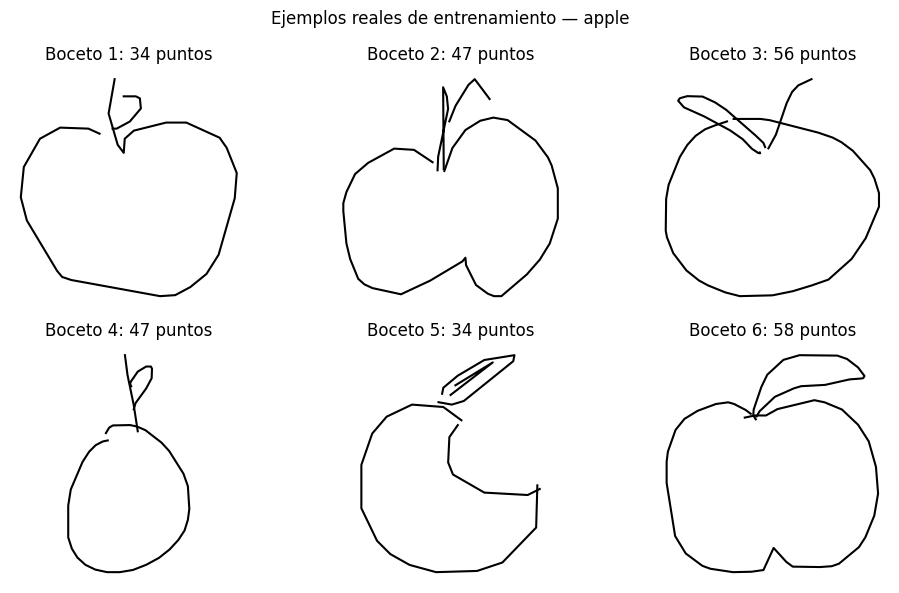

Longitudes originales del conjunto de entrenamiento:
Mínimo: 22
Mediana: 37.0
Máximo: 62
Bocetos con más de 200 puntos: 0
Porcentaje que necesitará truncado: 0.00%


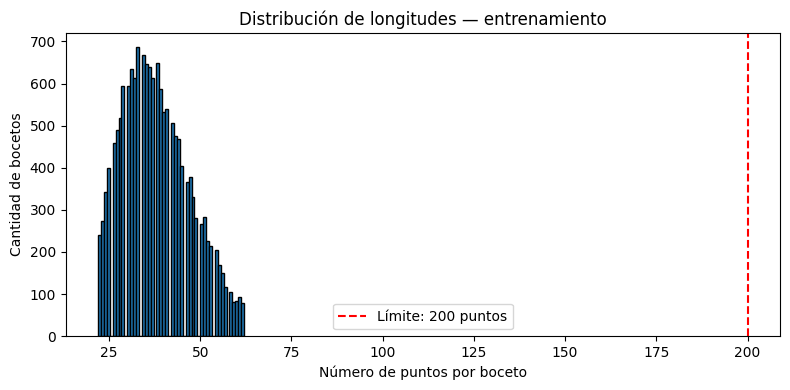

In [4]:
def draw_stroke3(sketch, ax):
    sketch = np.asarray(sketch, dtype=np.float32)
    coords = np.cumsum(sketch[:, :2], axis=0)

    start = 0

    for i in range(len(sketch)):
        if sketch[i, 2] == 1:
            ax.plot(
                coords[start:i + 1, 0],
                -coords[start:i + 1, 1],
                color="black",
                linewidth=1.5
            )
            start = i + 1

    # Mostrar también el último trazo si no termina con pen_lift=1.
    if start < len(sketch):
        ax.plot(
            coords[start:, 0],
            -coords[start:, 1],
            color="black",
            linewidth=1.5
        )

    ax.set_aspect("equal")
    ax.axis("off")


fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for i, ax in enumerate(axes.flat):
    sketch = train_sketches[i]
    draw_stroke3(sketch, ax)
    ax.set_title(f"Boceto {i + 1}: {len(sketch)} puntos")

fig.suptitle("Ejemplos reales de entrenamiento — apple")
plt.tight_layout()
plt.show()

train_lengths = np.array([len(s) for s in train_sketches])

print("Longitudes originales del conjunto de entrenamiento:")
print("Mínimo:", train_lengths.min())
print("Mediana:", float(np.median(train_lengths)))
print("Máximo:", train_lengths.max())
print("Bocetos con más de 200 puntos:", int((train_lengths > MAX_POINTS).sum()))
print(
    "Porcentaje que necesitará truncado:",
    f"{100 * (train_lengths > MAX_POINTS).mean():.2f}%"
)

plt.figure(figsize=(8, 4))
plt.hist(train_lengths, bins=50, edgecolor="black")
plt.axvline(
    MAX_POINTS,
    color="red",
    linestyle="--",
    label="Límite: 200 puntos"
)
plt.title("Distribución de longitudes — entrenamiento")
plt.xlabel("Número de puntos por boceto")
plt.ylabel("Cantidad de bocetos")
plt.legend()
plt.tight_layout()
plt.show()

Los ejemplos se ven como manzanas y la exploración confirma que ninguno de los 16.000 bocetos de entrenamiento supera los 200 puntos: sus longitudes van de 22 a 62, con mediana de 37. Eso significa que no perderemos puntos de esos dibujos al aplicar el límite.

## 4. Preprocesamiento

Ahora, calcularemos la escala para normalizar los desplazamientos. Calcularemos esas escalas únicamente con entrenamiento. Luego usaremos los mismos valores en validación, prueba y generación.

Además, fijaremos una convención: reservaremos una posición para el estado “fin del dibujo”. Así, cada secuencia tendrá como máximo 199 movimientos y una señal final, sin superar 200 posiciones. En nuestro conjunto de entrenamiento esto no recortará ningún boceto, porque el más largo tiene 62 puntos.

In [5]:
# Reservamos una posición para la señal de fin del dibujo.
MAX_DRAW_POINTS = MAX_POINTS - 1

# Reunimos únicamente desplazamientos reales de entrenamiento.
train_xy = np.concatenate(
    [
        np.asarray(sketch[:MAX_DRAW_POINTS, :2], dtype=np.float32)
        for sketch in train_sketches
    ],
    axis=0
)

assert train_xy.ndim == 2
assert train_xy.shape[1] == 2
assert np.isfinite(train_xy).all()

# Una desviación estándar para cada eje.
xy_scale = train_xy.std(axis=0, dtype=np.float64).astype(np.float32)

assert np.isfinite(xy_scale).all()
assert (xy_scale > 0).all()

normalized_train_xy = train_xy / xy_scale

print("Escalas calculadas solo con entrenamiento.")
print("Cantidad de movimientos utilizados:", len(train_xy))
print("Escala de delta_x:", float(xy_scale[0]))
print("Escala de delta_y:", float(xy_scale[1]))
print(
    "Desviaciones estándar después de normalizar:",
    normalized_train_xy.std(axis=0, dtype=np.float64)
)
print("Máximo de movimientos por dibujo:", MAX_DRAW_POINTS)
print("Máximo de posiciones, incluyendo fin:", MAX_POINTS)

Escalas calculadas solo con entrenamiento.
Cantidad de movimientos utilizados: 605898
Escala de delta_x: 27.67275047302246
Escala de delta_y: 32.68901824951172
Desviaciones estándar después de normalizar: [1.00000002 1.        ]
Máximo de movimientos por dibujo: 199
Máximo de posiciones, incluyendo fin: 200


Las desviaciones estándar quedaron prácticamente en 1 para ambos ejes. La normalización está comprobada.

Ahora construiremos la representación stroke-5, el relleno y los pares entrada–objetivo.
Cada punto tendrá 5 valores:
* [delta_x_normalizado, delta_y_normalizado, dibujar, levantar, terminar]

Los últimos tres valores indican el estado mediante un único 1.

Además, usaremos estas reglas:
* Conservamos hasta 199 movimientos y añadimos una señal de fin.
* Rellenamos las posiciones restantes hasta llegar a 200.
* La primera señal de fin sí es un objetivo válido que el modelo debe aprender.
* Las posiciones posteriores son relleno y no cuentan.
* Para la regresión usaremos solo movimientos reales: la señal de fin no representa un desplazamiento observado.

Por eso tendremos dos máscaras: una para clasificación (incluye el fin) y otra para coordenadas (solo movimientos).

In [6]:
def prepare_sketch(sketch):
    stroke3 = np.asarray(sketch, dtype=np.float32)[:MAX_DRAW_POINTS]

    assert stroke3.ndim == 2 and stroke3.shape[1] == 3
    assert len(stroke3) > 0
    assert np.isfinite(stroke3).all()
    assert np.isin(stroke3[:, 2], [0, 1]).all()

    n_moves = len(stroke3)
    length = n_moves + 1  # Movimientos + una señal de fin.

    # Objetivos: por defecto, todas las posiciones indican fin.
    targets = np.zeros((MAX_POINTS, 5), dtype=np.float32)
    targets[:, 4] = 1.0

    # Sustituimos las posiciones que corresponden a movimientos reales.
    targets[:n_moves, :2] = stroke3[:, :2] / xy_scale
    targets[:n_moves, 2] = 1.0 - stroke3[:, 2]
    targets[:n_moves, 3] = stroke3[:, 2]
    targets[:n_moves, 4] = 0.0

    # Entrada desplazada: inicio, punto 1, punto 2, ...
    inputs = np.zeros_like(targets)
    inputs[0] = [0, 0, 1, 0, 0]
    inputs[1:] = targets[:-1]

    # Clasificación: movimientos y primera señal de fin.
    mask_pen = np.arange(MAX_POINTS) < length

    # Regresión: únicamente movimientos reales.
    mask_xy = np.arange(MAX_POINTS) < n_moves

    return {
        "x": inputs,
        "y": targets,
        "mask_pen": mask_pen,
        "mask_xy": mask_xy,
        "length": length,
        "n_moves": n_moves,
    }


example = prepare_sketch(train_sketches[0])

assert example["x"].shape == (200, 5)
assert example["y"].shape == (200, 5)
assert example["mask_pen"].sum() == example["length"]
assert example["mask_xy"].sum() == example["n_moves"]

# Cada posición tiene exactamente un estado activo.
assert np.all(example["y"][:, 2:].sum(axis=1) == 1)

# El objetivo de fin está incluido; el relleno posterior, excluido.
end_index = example["n_moves"]
assert example["y"][end_index, 4] == 1
assert example["mask_pen"][end_index]
assert not example["mask_pen"][end_index + 1:].any()

# La entrada contiene el punto anterior, no el que debe predecir.
assert np.array_equal(example["x"][1:], example["y"][:-1])

print("Verificaciones superadas.")
print("Forma de las entradas:", example["x"].shape)
print("Forma de los objetivos:", example["y"].shape)
print("Movimientos reales:", example["n_moves"])
print("Posiciones válidas para clasificación:", int(example["mask_pen"].sum()))
print("Posiciones válidas para regresión:", int(example["mask_xy"].sum()))
print("Posiciones de relleno:", int((~example["mask_pen"]).sum()))

print("\nPrimera entrada (señal de inicio):")
print(example["x"][0])

print("\nPrimer objetivo (primer movimiento):")
print(example["y"][0])

print("\nObjetivo de fin:")
print(example["y"][end_index])

Verificaciones superadas.
Forma de las entradas: (200, 5)
Forma de los objetivos: (200, 5)
Movimientos reales: 34
Posiciones válidas para clasificación: 35
Posiciones válidas para regresión: 34
Posiciones de relleno: 165

Primera entrada (señal de inicio):
[0. 0. 1. 0. 0.]

Primer objetivo (primer movimiento):
[-0.4697762  -0.33650446  1.          0.          0.        ]

Objetivo de fin:
[0. 0. 0. 0. 1.]


La prueba de un dibujo pasó todas las verificaciones. Tenemos 34 movimientos, una señal de fin válida y 165 posiciones de relleno excluidas.

Ahora aplicaremos el mismo procedimiento a los 20.000 bocetos, sin cambiar la selección ni recalcular las escalas manteniendo separados entrenamiento, validación y prueba.

Cada conjunto tendrá los siguientes componentes:
| Nombre   | Contenido                                                   |
| -------- | ----------------------------------------------------------- |
| x        | Secuencias de entrada, empezando por la señal de inicio.    |
| y        | Secuencias objetivo: movimientos y señal de fin.            |
| mask_pen | Posiciones que cuentan para clasificar el estado del lápiz. |
| mask_xy  | Movimientos que cuentan para predecir coordenadas.          |
| length   | Cantidad de movimientos más una señal de fin.               |
| n_moves  | Cantidad de movimientos conservados.                        |

Las máscaras quedan guardadas junto con los datos para aplicarlas posteriormente tanto a las pérdidas como a las métricas.

Por otro lado, preparar `test_data` no significa evaluar ni ajustar el modelo con prueba: solo le aplicamos una transformación ya definida, usando las escalas calculadas con entrenamiento.

In [7]:
def prepare_collection(sketches, name):
    n = len(sketches)

    arrays = {
        "x": np.empty((n, MAX_POINTS, 5), dtype=np.float32),
        "y": np.empty((n, MAX_POINTS, 5), dtype=np.float32),
        "mask_pen": np.empty((n, MAX_POINTS), dtype=bool),
        "mask_xy": np.empty((n, MAX_POINTS), dtype=bool),
        "length": np.empty(n, dtype=np.int64),
        "n_moves": np.empty(n, dtype=np.int64),
    }

    for i, sketch in enumerate(sketches):
        prepared = prepare_sketch(sketch)

        for key in arrays:
            arrays[key][i] = prepared[key]

    # Verificaciones sobre toda la colección.
    assert np.isfinite(arrays["x"]).all()
    assert np.isfinite(arrays["y"]).all()
    assert np.all(arrays["length"] <= MAX_POINTS)

    assert np.array_equal(
        arrays["mask_pen"].sum(axis=1),
        arrays["length"]
    )
    assert np.array_equal(
        arrays["mask_xy"].sum(axis=1),
        arrays["n_moves"]
    )
    assert np.all(arrays["y"][:, :, 2:].sum(axis=2) == 1)

    # Una señal de fin válida por boceto, sin contar el relleno.
    valid_end_signals = (
        (arrays["y"][:, :, 4] == 1) & arrays["mask_pen"]
    ).sum(axis=1)

    assert np.all(valid_end_signals == 1)

    # Convertimos los arreglos a tensores de PyTorch en CPU.
    tensors = {
        key: torch.from_numpy(value)
        for key, value in arrays.items()
    }

    print(f"\n{name}")
    print("Entradas:", tuple(tensors["x"].shape))
    print("Objetivos:", tuple(tensors["y"].shape))
    print("Movimientos reales:", int(tensors["mask_xy"].sum()))
    print(
        "Posiciones válidas de clasificación:",
        int(tensors["mask_pen"].sum())
    )
    print(
        "Longitud máxima incluyendo fin:",
        int(tensors["length"].max())
    )
    print("Verificaciones: OK")

    return tensors


train_data = prepare_collection(train_sketches, "ENTRENAMIENTO")
valid_data = prepare_collection(valid_sketches, "VALIDACIÓN")
test_data = prepare_collection(test_sketches, "PRUEBA")

print("\nPreprocesamiento de los tres conjuntos completado.")


ENTRENAMIENTO
Entradas: (16000, 200, 5)
Objetivos: (16000, 200, 5)
Movimientos reales: 605898
Posiciones válidas de clasificación: 621898
Longitud máxima incluyendo fin: 63
Verificaciones: OK

VALIDACIÓN
Entradas: (2000, 200, 5)
Objetivos: (2000, 200, 5)
Movimientos reales: 75968
Posiciones válidas de clasificación: 77968
Longitud máxima incluyendo fin: 63
Verificaciones: OK

PRUEBA
Entradas: (2000, 200, 5)
Objetivos: (2000, 200, 5)
Movimientos reales: 75836
Posiciones válidas de clasificación: 77836
Longitud máxima incluyendo fin: 63
Verificaciones: OK

Preprocesamiento de los tres conjuntos completado.


Como se pudo observar, los tres conjuntos quedaron preparados y pasaron las verificaciones. Todos tienen una longitud máxima de 63 posiciones contando el fin, así que tampoco se truncaron dibujos de validación ni de prueba.

Ahora prepararemos los lotes que recibirá la red: grupos de 128 bocetos. Para hacerlo usaremos `TensorDataset`, que mantiene alineadas las entradas, los objetivos y las máscaras, y `DataLoader`, que los entrega por lotes.

## 5. Split train / validación / prueba

Se seleccionaron aleatoriamente, sin reemplazo y con semilla 42:

- 16.000 bocetos del conjunto original `train`.
- 2.000 bocetos del conjunto original `valid`.
- 2.000 bocetos del conjunto original `test`.

La selección se realizó en la sección 3, antes de la exploración y del
preprocesamiento, sin mezclar los conjuntos originales.

Las escalas de normalización se calcularon exclusivamente con entrenamiento
y se aplicaron sin modificación a validación y prueba.

Entrenamiento se utiliza para actualizar los parámetros del modelo.
Validación se utiliza para seleccionar el mejor modelo y monitorear el
sobreajuste. Prueba se reserva para la evaluación final.

A continuación se organizan los conjuntos en lotes de 128 bocetos.
Solo se cambia el orden de los ejemplos de entrenamiento; nunca se
modifica el orden de los puntos dentro de un dibujo.

In [8]:
BATCH_SIZE = 128 #entrega hasta 128 dibujos en cada lote.

def make_tensor_dataset(data):
    return TensorDataset(
        data["x"],
        data["y"],
        data["mask_pen"],
        data["mask_xy"],
        data["length"],
    )


train_dataset = make_tensor_dataset(train_data)
valid_dataset = make_tensor_dataset(valid_data)
test_dataset = make_tensor_dataset(test_data)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True, #cambia el orden de los dibujos de entrenamiento en cada recorrido; no cambia sus puntos internos.
    drop_last=False, #conserva también el último lote aunque tenga menos de 128 dibujos.
    num_workers=0,
    generator=loader_generator,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
)

# Comprobamos un lote de entrenamiento.
x_batch, y_batch, mask_pen_batch, mask_xy_batch, lengths_batch = (
    next(iter(train_loader))
)

assert x_batch.shape == (BATCH_SIZE, MAX_POINTS, 5)
assert y_batch.shape == x_batch.shape
assert mask_pen_batch.dtype == torch.bool
assert mask_xy_batch.dtype == torch.bool

assert torch.equal(
    mask_pen_batch.sum(dim=1),
    lengths_batch
)
assert torch.equal(
    mask_xy_batch.sum(dim=1),
    lengths_batch - 1
)

print("Cargadores creados correctamente.")
print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de validación:", len(valid_loader))
print("Lotes de prueba:", len(test_loader))

print("\nPrimer lote de entrenamiento:")
print("Entradas:", tuple(x_batch.shape))
print("Objetivos:", tuple(y_batch.shape))
print("Máscara de estados:", tuple(mask_pen_batch.shape))
print("Máscara de coordenadas:", tuple(mask_xy_batch.shape))
print("Longitudes:", tuple(lengths_batch.shape))
print("Verificaciones: OK")

Cargadores creados correctamente.
Lotes de entrenamiento: 125
Lotes de validación: 16
Lotes de prueba: 16

Primer lote de entrenamiento:
Entradas: (128, 200, 5)
Objetivos: (128, 200, 5)
Máscara de estados: (128, 200)
Máscara de coordenadas: (128, 200)
Longitudes: (128,)
Verificaciones: OK


Como se puede observar, los lotes tienen las dimensiones correctas y las máscaras están alineadas. Ahora crearemos la LSTM y comprobaremos que produce dos desplazamientos y tres puntuaciones de estado por cada posición.

Todavía no entrenaremos: este paso verifica únicamente la arquitectura y su ejecución en la GPU.

## 6. Arquitectura y creación del modelo

In [9]:
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

HIDDEN_SIZE = 128

class SketchLSTM(nn.Module):
    def __init__(self, hidden_size=128):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=5,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=False,
        )

        self.xy_head = nn.Linear(hidden_size, 2)
        self.pen_head = nn.Linear(hidden_size, 3)

    def forward(self, x, state=None):
        hidden_sequence, next_state = self.lstm(x, state)

        xy_pred = self.xy_head(hidden_sequence)
        pen_logits = self.pen_head(hidden_sequence)

        return xy_pred, pen_logits, next_state


model = SketchLSTM(hidden_size=HIDDEN_SIZE).to(device)

n_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print("\nDispositivo:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Parámetros entrenables:", f"{n_parameters:,}")

# Prueba de ejecución: todavía no actualizamos los pesos.
model.eval()

with torch.no_grad():
    xy_pred, pen_logits, next_state = model(
        x_batch.to(device)
    )

assert xy_pred.shape == (BATCH_SIZE, MAX_POINTS, 2)
assert pen_logits.shape == (BATCH_SIZE, MAX_POINTS, 3)
assert torch.isfinite(xy_pred).all()
assert torch.isfinite(pen_logits).all()

print("\nPrueba con un lote:")
print("Coordenadas predichas:", tuple(xy_pred.shape))
print("Logits de estados:", tuple(pen_logits.shape))
print("Estado oculto final:", tuple(next_state[0].shape))
print("Memoria final:", tuple(next_state[1].shape))
print("Verificaciones: OK")

SketchLSTM(
  (lstm): LSTM(5, 128, batch_first=True)
  (xy_head): Linear(in_features=128, out_features=2, bias=True)
  (pen_head): Linear(in_features=128, out_features=3, bias=True)
)

Dispositivo: cuda
GPU: Tesla T4
Parámetros entrenables: 69,765

Prueba con un lote:
Coordenadas predichas: (128, 200, 2)
Logits de estados: (128, 200, 3)
Estado oculto final: (1, 128, 128)
Memoria final: (1, 128, 128)
Verificaciones: OK


PyTorch devuelve tanto las representaciones de todos los pasos como el estado oculto y la memoria finales de la LSTM.

Los logits todavía no son probabilidades. Dejaremos esa conversión fuera del modelo; más adelante la aplicaremos cuando necesitemos seleccionar el estado durante la generación.

Ahora vamos a implementar la pérdida y comprobar que el relleno no la afecta. Este paso todavía no entrena el modelo: verifica que la señal con la que aprenderá esté bien construida.

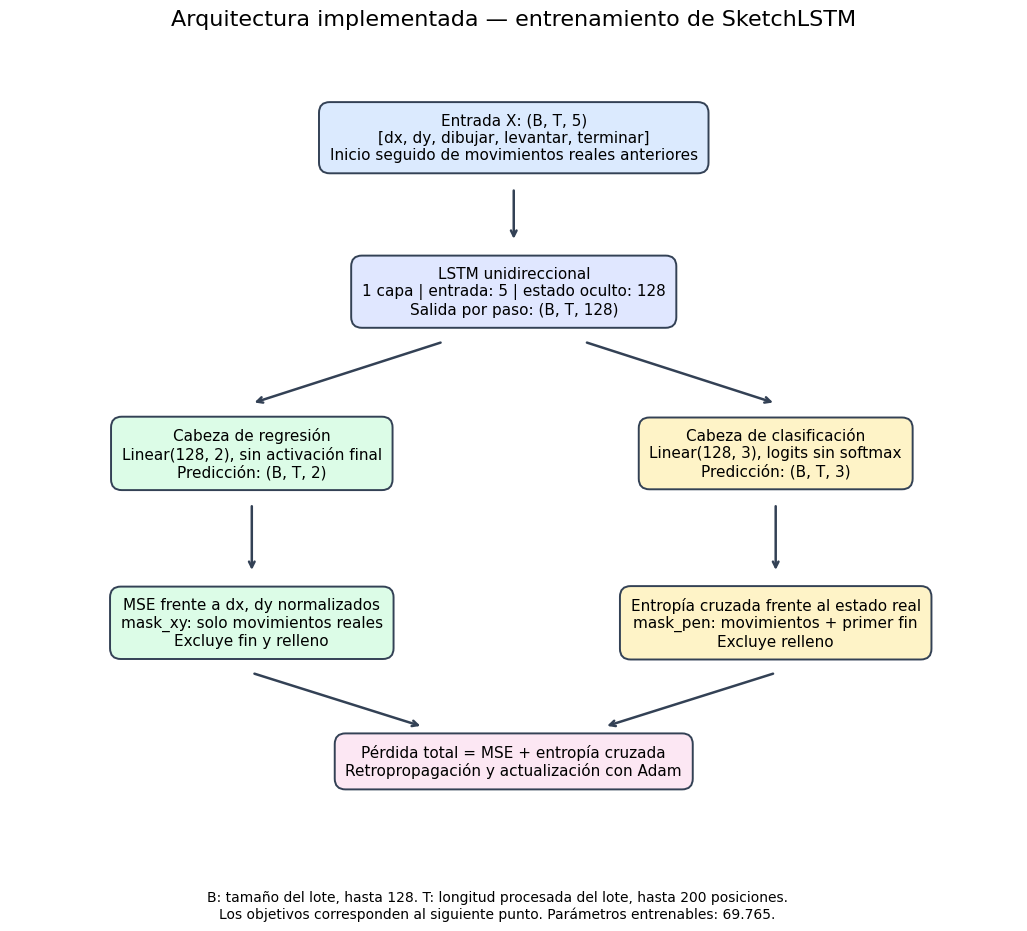

Diagrama guardado y verificado.
Archivo: /content/drive/MyDrive/MAPLN_Microproyecto_1/respaldo_juan_david/entrenamiento_apple/entregables/diagrama_arquitectura.png
Tamaño: 254509 bytes


In [10]:
# Esta celda no modifica ni vuelve a crear el modelo.

diagram_drive_root = Path("/content/drive/MyDrive")

if diagram_drive_root.is_dir():
    diagram_dir = (
        diagram_drive_root
        / "MAPLN_Microproyecto_1"
        / "respaldo_juan_david"
        / "entrenamiento_apple"
        / "entregables"
    )
else:
    diagram_dir = Path("/content/entrenamiento_apple/entregables")

diagram_dir.mkdir(parents=True, exist_ok=True)
DIAGRAM_PATH = diagram_dir / "diagrama_arquitectura.png"

fig, ax = plt.subplots(figsize=(13, 10))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

def diagram_box(x, y, text, color):
    ax.text(
        x, y, text,
        ha="center",
        va="center",
        fontsize=11,
        transform=ax.transAxes,
        bbox={
            "boxstyle": "round,pad=0.7",
            "facecolor": color,
            "edgecolor": "#334155",
            "linewidth": 1.4,
        },
    )

def diagram_arrow(start, end):
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        xycoords="axes fraction",
        textcoords="axes fraction",
        arrowprops={
            "arrowstyle": "->",
            "linewidth": 1.8,
            "color": "#334155",
        },
    )

ax.set_title(
    "Arquitectura implementada — entrenamiento de SketchLSTM",
    fontsize=16,
    pad=20,
)

diagram_box(
    0.50, 0.89,
    "Entrada X: (B, T, 5)\n"
    "[dx, dy, dibujar, levantar, terminar]\n"
    "Inicio seguido de movimientos reales anteriores",
    "#dbeafe",
)

diagram_box(
    0.50, 0.69,
    "LSTM unidireccional\n"
    "1 capa | entrada: 5 | estado oculto: 128\n"
    "Salida por paso: (B, T, 128)",
    "#e0e7ff",
)

diagram_box(
    0.24, 0.48,
    "Cabeza de regresión\n"
    "Linear(128, 2), sin activación final\n"
    "Predicción: (B, T, 2)",
    "#dcfce7",
)

diagram_box(
    0.76, 0.48,
    "Cabeza de clasificación\n"
    "Linear(128, 3), logits sin softmax\n"
    "Predicción: (B, T, 3)",
    "#fef3c7",
)

diagram_box(
    0.24, 0.26,
    "MSE frente a dx, dy normalizados\n"
    "mask_xy: solo movimientos reales\n"
    "Excluye fin y relleno",
    "#dcfce7",
)

diagram_box(
    0.76, 0.26,
    "Entropía cruzada frente al estado real\n"
    "mask_pen: movimientos + primer fin\n"
    "Excluye relleno",
    "#fef3c7",
)

diagram_box(
    0.50, 0.08,
    "Pérdida total = MSE + entropía cruzada\n"
    "Retropropagación y actualización con Adam",
    "#fce7f3",
)

diagram_arrow((0.50, 0.825), (0.50, 0.755))
diagram_arrow((0.43, 0.625), (0.24, 0.545))
diagram_arrow((0.57, 0.625), (0.76, 0.545))
diagram_arrow((0.24, 0.415), (0.24, 0.325))
diagram_arrow((0.76, 0.415), (0.76, 0.325))
diagram_arrow((0.24, 0.195), (0.41, 0.125))
diagram_arrow((0.76, 0.195), (0.59, 0.125))

fig.text(
    0.5, 0.015,
    "B: tamaño del lote, hasta 128. "
    "T: longitud procesada del lote, hasta 200 posiciones.\n"
    "Los objetivos corresponden al siguiente punto. "
    "Parámetros entrenables: 69.765.",
    ha="center",
    fontsize=10,
)

fig.savefig(
    DIAGRAM_PATH,
    dpi=180,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

assert DIAGRAM_PATH.is_file()
assert DIAGRAM_PATH.stat().st_size > 0

print("Diagrama guardado y verificado.")
print("Archivo:", DIAGRAM_PATH)
print("Tamaño:", DIAGRAM_PATH.stat().st_size, "bytes")

## 7. Entrenamiento del modelo
### Configuración del entrenamiento

| Hiperparámetro | Valor |
|---|---:|
| Tamaño del lote | 128 |
| Optimizador | Adam |
| Tasa de aprendizaje | 0.001 |
| Weight decay | 0.0001 |
| Máximo de épocas | 20 |
| Paciencia de parada temprana | 5 épocas |
| Norma máxima para recorte de gradientes | 1.0 |
| Peso de la pérdida de coordenadas | 1 |
| Peso de la pérdida de estados | 1 |

Se utilizaron 125 lotes por época para recorrer los 16.000 bocetos
de entrenamiento. El orden de los bocetos se reorganiza entre épocas,
sin modificar el orden de sus puntos.

En cada lote se limpian los gradientes, se realiza la predicción,
se calcula la pérdida compuesta, se ejecuta la retropropagación,
se recortan los gradientes y se actualizan los parámetros con Adam.

Las secuencias se almacenan con 200 posiciones. Para reducir cómputo,
cada lote se procesa únicamente hasta su longitud válida máxima,
eliminando las columnas finales que son relleno para todos sus ejemplos.
Las máscaras siguen excluyendo el relleno restante dentro del lote.

### Validación y selección del modelo

Después de cada época se evalúa el conjunto completo de validación
sin calcular gradientes ni actualizar los parámetros.

Las pérdidas se agregan globalmente: el MSE se pondera por el número
de coordenadas válidas y la entropía cruzada por el número de estados
válidos. No se promedian los lotes con igual peso cuando tienen
diferentes cantidades de puntos.

Se guarda el modelo con menor pérdida total de validación. La parada
temprana se activa si transcurren cinco épocas consecutivas sin mejora.

En la ejecución reportada se completaron las 20 épocas y la mejor fue
la época 20, con pérdida de validación de 0.559098. La parada temprana
estaba implementada, pero no llegó a activarse.

### Medidas de control y estabilidad

Se utilizó weight decay como regularización y se monitoreó la pérdida
de validación para detectar una posible separación respecto a
entrenamiento. El recorte de gradientes se utilizó como medida de
estabilidad de la optimización, no como garantía contra el sobreajuste.

La prueba se reservó para el reporte final. No se modificaron los
hiperparámetros a partir de sus resultados.

In [11]:
def compute_loss(
    xy_pred,
    pen_logits,
    targets,
    mask_pen,
    mask_xy,
):
    # Promedio sobre movimientos reales y sus dos coordenadas.
    loss_xy = nn.functional.mse_loss(
        xy_pred[mask_xy],
        targets[..., :2][mask_xy],
        reduction="mean",
    )

    # Convertimos los tres indicadores en una clase: 0, 1 o 2.
    pen_targets = targets[..., 2:].argmax(dim=-1)

    # Promedio sobre movimientos reales y primera señal de fin.
    loss_pen = nn.functional.cross_entropy(
        pen_logits[mask_pen],
        pen_targets[mask_pen],
        reduction="mean",
    )

    loss_total = loss_xy + loss_pen

    return loss_total, loss_xy, loss_pen


# Probamos con el mismo lote, sin actualizar pesos.
model.eval()

with torch.no_grad():
    x_gpu = x_batch.to(device)
    y_gpu = y_batch.to(device)
    mask_pen_gpu = mask_pen_batch.to(device)
    mask_xy_gpu = mask_xy_batch.to(device)

    xy_pred, pen_logits, _ = model(x_gpu)

    loss_total, loss_xy, loss_pen = compute_loss(
        xy_pred,
        pen_logits,
        y_gpu,
        mask_pen_gpu,
        mask_xy_gpu,
    )

    assert torch.isfinite(loss_total)

    # Alteramos únicamente predicciones en posiciones excluidas.
    xy_changed = xy_pred.clone()
    pen_changed = pen_logits.clone()

    xy_changed[~mask_xy_gpu] = 9999.0
    pen_changed[~mask_pen_gpu] = torch.tensor(
        [9999.0, -9999.0, 0.0],
        device=device,
        dtype=pen_changed.dtype,
    )

    changed_total, changed_xy, changed_pen = compute_loss(
        xy_changed,
        pen_changed,
        y_gpu,
        mask_pen_gpu,
        mask_xy_gpu,
    )

    assert torch.allclose(loss_xy, changed_xy)
    assert torch.allclose(loss_pen, changed_pen)
    assert torch.allclose(loss_total, changed_total)

print(f"Pérdida de coordenadas: {loss_xy.item():.6f}")
print(f"Pérdida de estados: {loss_pen.item():.6f}")
print(f"Pérdida total: {loss_total.item():.6f}")
print(f"Total alterando posiciones excluidas: {changed_total.item():.6f}")
print("Prueba de máscaras: OK")

Pérdida de coordenadas: 0.911843
Pérdida de estados: 1.080513
Pérdida total: 1.992355
Total alterando posiciones excluidas: 1.992355
Prueba de máscaras: OK


In [12]:
MAX_EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

assert device.type == "cuda", (
    "No hay GPU activa. Revisa el entorno antes de entrenar."
)

# Usamos Drive si está montado; si no, guardamos localmente.
drive_root = Path("/content/drive/MyDrive")

if drive_root.is_dir():
    RUN_DIR = (
        drive_root
        / "MAPLN_Microproyecto_1"
        / "respaldo_juan_david"
        / "entrenamiento_apple"
    )
else:
    RUN_DIR = Path("/content/entrenamiento_apple")
    print(
        "AVISO: Drive no está montado. El modelo se guardará "
        "solo en la sesión de Colab; habrá que descargarlo."
    )

RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = RUN_DIR / "best_model.pt"

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)


def run_epoch(loader, training):
    model.train(training)

    squared_error_sum = 0.0
    cross_entropy_sum = 0.0
    n_coordinates = 0
    n_pen_positions = 0

    for x, y, mask_pen, mask_xy, lengths in loader:
        # Eliminamos solo columnas finales de relleno del lote.
        max_length = int(lengths.max())

        x = x[:, :max_length].to(device)
        y = y[:, :max_length].to(device)
        mask_pen = mask_pen[:, :max_length].to(device)
        mask_xy = mask_xy[:, :max_length].to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            xy_pred, pen_logits, _ = model(x)

            loss, loss_xy, loss_pen = compute_loss(
                xy_pred, pen_logits, y, mask_pen, mask_xy
            )

            if not torch.isfinite(loss):
                raise RuntimeError("Se detectó una pérdida no finita.")

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                optimizer.step()

        # Agregación global por coordenadas y posiciones válidas.
        batch_coordinates = int(mask_xy.sum().item()) * 2
        batch_pen_positions = int(mask_pen.sum().item())

        squared_error_sum += loss_xy.item() * batch_coordinates
        cross_entropy_sum += loss_pen.item() * batch_pen_positions

        n_coordinates += batch_coordinates
        n_pen_positions += batch_pen_positions

    mse = squared_error_sum / n_coordinates
    ce = cross_entropy_sum / n_pen_positions

    return {"loss": mse + ce, "mse": mse, "ce": ce}


history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

print("Carpeta de guardado:", RUN_DIR)
print("Inicio del entrenamiento.", flush=True)

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.perf_counter()

    train_metrics = run_epoch(train_loader, training=True)
    valid_metrics = run_epoch(valid_loader, training=False)

    history.append({
        "epoch": epoch,
        "train": train_metrics,
        "valid": valid_metrics,
    })

    improved = valid_metrics["loss"] < best_val_loss

    if improved:
        best_val_loss = valid_metrics["loss"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch,
            "best_val_loss": best_val_loss,
            "hidden_size": HIDDEN_SIZE,
            "xy_scale": torch.from_numpy(xy_scale.copy()),
            "category": CATEGORY,
            "seed": SEED,
            "max_points": MAX_POINTS,
            "history": history,
        }, BEST_MODEL_PATH)
    else:
        epochs_without_improvement += 1

    elapsed = time.perf_counter() - start

    print(
        f"Época {epoch:02d}/{MAX_EPOCHS} | "
        f"train={train_metrics['loss']:.4f} | "
        f"valid={valid_metrics['loss']:.4f} | "
        f"MSE valid={valid_metrics['mse']:.4f} | "
        f"CE valid={valid_metrics['ce']:.4f} | "
        f"{elapsed:.1f} s"
        + (" | mejor modelo guardado" if improved else ""),
        flush=True,
    )

    if epochs_without_improvement >= PATIENCE:
        print("Parada temprana: validación dejó de mejorar.")
        break

# Conservamos también la historia completa del entrenamiento.
torch.save(history, RUN_DIR / "history.pt")

# Recuperamos los pesos de la mejor época, no los de la última.
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nEntrenamiento finalizado.")
print("Mejor época:", best_epoch)
print(f"Mejor pérdida de validación: {best_val_loss:.6f}")
print("Modelo recuperado:", BEST_MODEL_PATH)

Carpeta de guardado: /content/drive/MyDrive/MAPLN_Microproyecto_1/respaldo_juan_david/entrenamiento_apple
Inicio del entrenamiento.
Época 01/20 | train=1.2268 | valid=0.9487 | MSE valid=0.6384 | CE valid=0.3103 | 2.7 s | mejor modelo guardado
Época 02/20 | train=0.9266 | valid=0.8351 | MSE valid=0.5701 | CE valid=0.2650 | 1.0 s | mejor modelo guardado
Época 03/20 | train=0.8178 | valid=0.7403 | MSE valid=0.5037 | CE valid=0.2366 | 1.0 s | mejor modelo guardado
Época 04/20 | train=0.7306 | valid=0.6752 | MSE valid=0.4486 | CE valid=0.2266 | 1.0 s | mejor modelo guardado
Época 05/20 | train=0.6807 | valid=0.6395 | MSE valid=0.4192 | CE valid=0.2203 | 1.0 s | mejor modelo guardado
Época 06/20 | train=0.6531 | valid=0.6175 | MSE valid=0.4012 | CE valid=0.2163 | 1.0 s | mejor modelo guardado
Época 07/20 | train=0.6352 | valid=0.6047 | MSE valid=0.3907 | CE valid=0.2140 | 1.0 s | mejor modelo guardado
Época 08/20 | train=0.6221 | valid=0.6018 | MSE valid=0.3898 | CE valid=0.2120 | 1.0 s | me

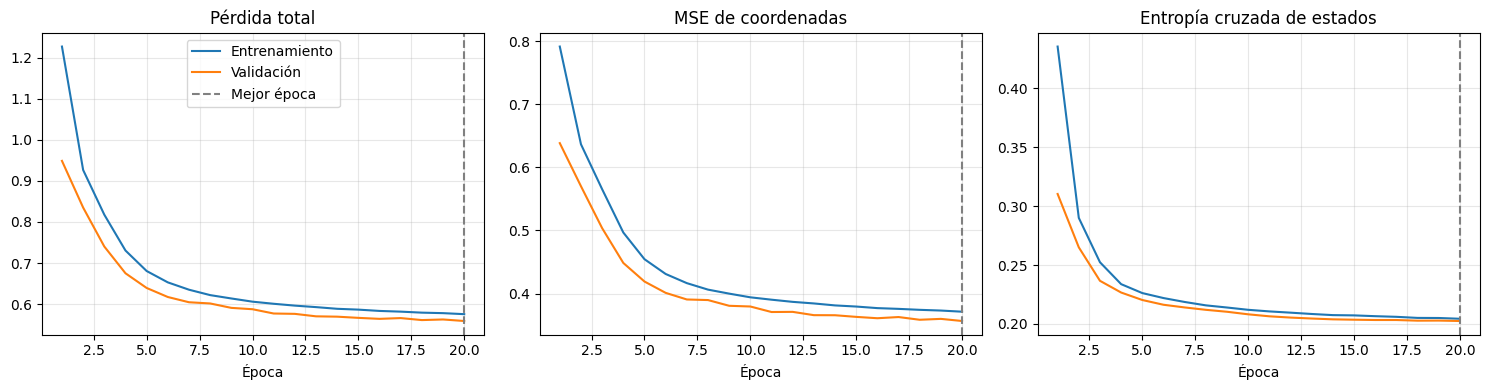

Curvas guardadas: /content/drive/MyDrive/MAPLN_Microproyecto_1/respaldo_juan_david/entrenamiento_apple/curvas_entrenamiento.png


In [13]:
epochs = [row["epoch"] for row in history]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "mse", "ce"],
    ["Pérdida total", "MSE de coordenadas", "Entropía cruzada de estados"],
):
    ax.plot(
        epochs,
        [row["train"][metric] for row in history],
        label="Entrenamiento",
    )
    ax.plot(
        epochs,
        [row["valid"][metric] for row in history],
        label="Validación",
    )
    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        label="Mejor época",
    )
    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()

curves_path = RUN_DIR / "curvas_entrenamiento.png"
fig.savefig(curves_path, dpi=150, bbox_inches="tight")

plt.show()
print("Curvas guardadas:", curves_path)

## 8. Evaluación del modelo

In [14]:
@torch.no_grad()
def evaluate_test():
    model.eval()

    squared_error_sum = 0.0
    cross_entropy_sum = 0.0
    n_coordinates = 0
    n_pen_positions = 0
    n_sketches = 0

    true_states = []
    predicted_states = []

    for x, y, mask_pen, mask_xy, lengths in test_loader:
        max_length = int(lengths.max())

        x = x[:, :max_length].to(device)
        y = y[:, :max_length].to(device)
        mask_pen = mask_pen[:, :max_length].to(device)
        mask_xy = mask_xy[:, :max_length].to(device)

        # Cada entrada contiene los puntos reales anteriores.
        xy_pred, pen_logits, _ = model(x)

        _, loss_xy, loss_pen = compute_loss(
            xy_pred, pen_logits, y, mask_pen, mask_xy
        )

        batch_coordinates = int(mask_xy.sum().item()) * 2
        batch_pen_positions = int(mask_pen.sum().item())

        squared_error_sum += loss_xy.item() * batch_coordinates
        cross_entropy_sum += loss_pen.item() * batch_pen_positions

        n_coordinates += batch_coordinates
        n_pen_positions += batch_pen_positions
        n_sketches += x.shape[0]

        actual = y[..., 2:].argmax(dim=-1)
        predicted = pen_logits.argmax(dim=-1)

        true_states.append(actual[mask_pen].cpu().numpy())
        predicted_states.append(predicted[mask_pen].cpu().numpy())

    y_true = np.concatenate(true_states)
    y_pred = np.concatenate(predicted_states)

    mse = squared_error_sum / n_coordinates
    ce = cross_entropy_sum / n_pen_positions

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0,
    )

    metrics = {
        "test_mse_normalizado": float(mse),
        "test_f1_macro": float(macro_f1),
        "test_cross_entropy": float(ce),
        "test_loss": float(mse + ce),
        "n_bocetos": int(n_sketches),
        "n_movimientos": int(n_coordinates // 2),
        "n_estados_validos": int(n_pen_positions),
    }

    return metrics, y_true, y_pred


# Cargamos explícitamente el modelo elegido con validación.
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])

test_metrics, test_true_states, test_predicted_states = evaluate_test()

assert test_metrics["n_bocetos"] == N_TEST
assert test_metrics["n_movimientos"] == int(
    test_data["mask_xy"].sum()
)
assert test_metrics["n_estados_validos"] == int(
    test_data["mask_pen"].sum()
)
assert len(test_true_states) == test_metrics["n_estados_validos"]

print("EVALUACIÓN FINAL — CONJUNTO DE PRUEBA")
print("Época del modelo evaluado:", checkpoint["epoch"])

for name, value in test_metrics.items():
    if isinstance(value, float):
        print(f"{name}: {value:.6f}")
    else:
        print(f"{name}: {value}")

print("\nReporte por estado:")
print(classification_report(
    test_true_states,
    test_predicted_states,
    labels=[0, 1, 2],
    target_names=["dibujar", "levantar", "terminar"],
    digits=4,
    zero_division=0,
))

print("Matriz de confusión: filas=reales, columnas=predichos")
print("Orden: dibujar, levantar, terminar")
print(confusion_matrix(
    test_true_states,
    test_predicted_states,
    labels=[0, 1, 2],
))

metrics_path = RUN_DIR / "metricas_prueba.csv"

with open(metrics_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(test_metrics.keys()),
    )
    writer.writeheader()
    writer.writerow(test_metrics)

print("\nVerificaciones de conteos: OK")
print("Métricas guardadas:", metrics_path)

EVALUACIÓN FINAL — CONJUNTO DE PRUEBA
Época del modelo evaluado: 20
test_mse_normalizado: 0.361518
test_f1_macro: 0.614002
test_cross_entropy: 0.206157
test_loss: 0.567674
n_bocetos: 2000
n_movimientos: 75836
n_estados_validos: 77836

Reporte por estado:
              precision    recall  f1-score   support

     dibujar     0.9281    0.9870    0.9567     70424
    levantar     0.5845    0.0837    0.1464      5412
    terminar     0.7098    0.7705    0.7389      2000

    accuracy                         0.9186     77836
   macro avg     0.7408    0.6137    0.6140     77836
weighted avg     0.8986    0.9186    0.8947     77836

Matriz de confusión: filas=reales, columnas=predichos
Orden: dibujar, levantar, terminar
[[69508   322   594]
 [ 4923   453    36]
 [  459     0  1541]]

Verificaciones de conteos: OK
Métricas guardadas: /content/drive/MyDrive/MAPLN_Microproyecto_1/respaldo_juan_david/entrenamiento_apple/metricas_prueba.csv


### Resultados sobre el conjunto de prueba

Se evaluó el modelo de la época 20, seleccionado por su menor pérdida
de validación. La evaluación utilizó los 2.000 bocetos de prueba,
sin actualizar los parámetros del modelo.

| Métrica | Resultado |
|---|---:|
| MSE global de coordenadas normalizadas | 0.361518 |
| F1 macro de los tres estados | 0.614002 |
| Entropía cruzada de estados | 0.206157 |
| Pérdida total: MSE + entropía cruzada | 0.567674 |

El MSE se calculó sobre 75.836 movimientos reales y sus dos coordenadas.
La clasificación se evaluó sobre 77.836 posiciones: los movimientos
reales y una señal de fin por boceto. El relleno se excluyó de ambos
cálculos mediante máscaras.

Las predicciones se realizaron a un paso, usando los puntos reales
anteriores como contexto. Las métricas se agregaron globalmente por
punto, sin promediar los resultados por dibujo.

El F1 fue 0.9567 para dibujar, 0.1464 para levantar y 0.7389 para terminar.
La principal debilidad fue el bajo recall del estado levantar: solo se
identificaron correctamente 453 de sus 5.412 casos reales.

Aunque la exactitud global fue 0.9186, el F1 macro evidencia que el
desempeño no es uniforme entre las clases.

La pérdida de prueba (0.567674) fue cercana a la de validación
(0.559098). En esta ejecución no se observó una degradación marcada
entre ambos conjuntos, aunque esto no garantiza ausencia de
sobreajuste ni calidad visual en todas las generaciones.

## 9. Generación de ejemplos

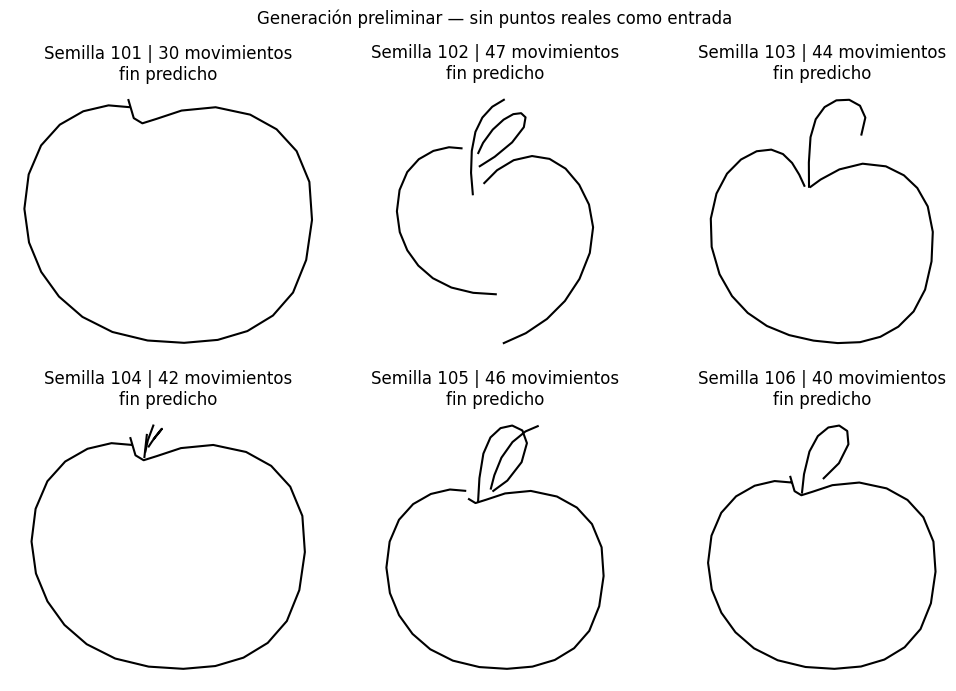

Semilla 101: 30 movimientos | Fin predicho: True
Semilla 102: 47 movimientos | Fin predicho: True
Semilla 103: 44 movimientos | Fin predicho: True
Semilla 104: 42 movimientos | Fin predicho: True
Semilla 105: 46 movimientos | Fin predicho: True
Semilla 106: 40 movimientos | Fin predicho: True

Vista preliminar guardada: /content/drive/MyDrive/MAPLN_Microproyecto_1/respaldo_juan_david/entrenamiento_apple/generacion_preliminar.png


In [15]:
@torch.no_grad()
def generate_sketch(seed, temperature=1.0):
    assert temperature > 0

    model.eval()

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    current = torch.tensor(
        [[[0.0, 0.0, 1.0, 0.0, 0.0]]],
        device=device,
    )

    state = None
    generated = []
    ended = False

    # Hasta 200 predicciones; la última posición se reserva
    # para permitir predecir fin tras hasta 199 movimientos.
    for step in range(MAX_POINTS):
        xy_pred, pen_logits, state = model(current, state)

        probabilities = torch.softmax(
            pen_logits[0, 0] / temperature,
            dim=-1,
        )

        pen_class = int(
            torch.multinomial(
                probabilities,
                num_samples=1,
                generator=generator,
            ).item()
        )

        if pen_class == 2:
            ended = True
            break

        if len(generated) >= MAX_DRAW_POINTS:
            break

        xy_normalized = xy_pred[0, 0]
        xy_original = (
            xy_normalized.cpu().numpy() * xy_scale
        )

        generated.append([
            float(xy_original[0]),
            float(xy_original[1]),
            float(pen_class == 1),
        ])

        # La siguiente entrada usa las coordenadas normalizadas
        # y el estado que acabamos de seleccionar.
        current = torch.zeros((1, 1, 5), device=device)
        current[0, 0, :2] = xy_normalized
        current[0, 0, 2 + pen_class] = 1.0

    stroke3 = np.asarray(
        generated, dtype=np.float32
    ).reshape(-1, 3)

    return stroke3, ended


preview_seeds = [101, 102, 103, 104, 105, 106]
preview_results = []

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, seed in zip(axes.flat, preview_seeds):
    sketch, ended = generate_sketch(
        seed=seed,
        temperature=1.0,
    )

    preview_results.append((seed, sketch, ended))

    if len(sketch) > 0:
        draw_stroke3(sketch, ax)
    else:
        ax.axis("off")
        ax.text(
            0.5, 0.5, "Fin sin movimientos",
            ha="center", va="center",
            transform=ax.transAxes,
        )

    ending = "fin predicho" if ended else "límite alcanzado"
    ax.set_title(
        f"Semilla {seed} | {len(sketch)} movimientos\n{ending}"
    )

fig.suptitle("Generación preliminar — sin puntos reales como entrada")
plt.tight_layout()

preview_path = RUN_DIR / "generacion_preliminar.png"
fig.savefig(preview_path, dpi=150, bbox_inches="tight")

plt.show()

for seed, sketch, ended in preview_results:
    print(
        f"Semilla {seed}: {len(sketch)} movimientos | "
        f"Fin predicho: {ended}"
    )

print("\nVista preliminar guardada:", preview_path)

In [16]:
ENTREGA_DIR = RUN_DIR / "entregables"
ENTREGA_DIR.mkdir(parents=True, exist_ok=True)

FINAL_SEEDS = [101, 102, 103]
FINAL_TEMPERATURE = 1.0

generation_records = []

for number, seed in enumerate(FINAL_SEEDS, start=1):
    sketch, ended = generate_sketch(
        seed=seed,
        temperature=FINAL_TEMPERATURE,
    )

    assert len(sketch) > 0, "Se generó un dibujo vacío."
    assert len(sketch) <= MAX_DRAW_POINTS
    assert np.isfinite(sketch).all()
    assert ended, "Esta secuencia no terminó mediante fin predicho."

    filename = f"boceto_apple_{number:02d}.png"
    image_path = ENTREGA_DIR / filename

    fig, ax = plt.subplots(figsize=(5, 5))
    draw_stroke3(sketch, ax)
    ax.margins(0.08)

    fig.savefig(
        image_path,
        dpi=200,
        bbox_inches="tight",
        pad_inches=0.15,
        facecolor="white",
    )
    plt.close(fig)

    assert image_path.is_file()
    assert image_path.stat().st_size > 0

    generation_records.append({
        "archivo": filename,
        "semilla": seed,
        "temperatura": FINAL_TEMPERATURE,
        "movimientos": len(sketch),
        "fin_predicho": ended,
    })

    print(
        f"{filename} | semilla={seed} | "
        f"movimientos={len(sketch)} | fin={ended} | "
        f"{image_path.stat().st_size} bytes"
    )

manifest_path = ENTREGA_DIR / "registro_generacion.csv"

with open(manifest_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(generation_records[0].keys()),
    )
    writer.writeheader()
    writer.writerows(generation_records)

print("\nTres PNG individuales guardados y verificados.")
print("Carpeta:", ENTREGA_DIR)
print("Registro de generación:", manifest_path)

boceto_apple_01.png | semilla=101 | movimientos=30 | fin=True | 28117 bytes
boceto_apple_02.png | semilla=102 | movimientos=47 | fin=True | 34130 bytes
boceto_apple_03.png | semilla=103 | movimientos=44 | fin=True | 33291 bytes

Tres PNG individuales guardados y verificados.
Carpeta: /content/drive/MyDrive/MAPLN_Microproyecto_1/respaldo_juan_david/entrenamiento_apple/entregables
Registro de generación: /content/drive/MyDrive/MAPLN_Microproyecto_1/respaldo_juan_david/entrenamiento_apple/entregables/registro_generacion.csv


## 10. Conclusiones

### Cumplimiento del objetivo

Se implementó y entrenó desde cero una LSTM unidireccional con dos
cabezas de salida para predecir desplazamientos y estados del lápiz.
El modelo permitió generar secuencias nuevas de la categoría `apple`
partiendo únicamente de una señal de inicio.

Se utilizaron 20.000 bocetos de una sola categoría, distribuidos en
16.000 de entrenamiento, 2.000 de validación y 2.000 de prueba,
respetando los conjuntos originales.

Se reservaron como máximo 199 movimientos y una señal de fin por
secuencia. Ningún boceto seleccionado necesitó truncado: la longitud
máxima procesada, incluyendo fin, fue de 63 posiciones en los tres
conjuntos.

### Resultados cuantitativos

En prueba se obtuvo un MSE global de coordenadas normalizadas de
0.361518, un F1 macro de 0.614002 y una pérdida total de 0.567674.

El desempeño fue desigual entre estados: F1 de 0.9567 para dibujar,
0.1464 para levantar y 0.7389 para terminar. La principal limitación
fue la detección de levantamientos del lápiz: 4.923 casos reales
de levantar se clasificaron como dibujar.

La exactitud global de 0.9186 no refleja por sí sola esta debilidad.
El F1 macro permitió observar el desempeño de las clases minoritarias.

### Generalización y sobreajuste

La pérdida de validación disminuyó de 0.9487 a 0.5591 durante las
20 épocas, sin un aumento sostenido al final. La pérdida de prueba
fue cercana a la de validación.

Estos resultados no muestran una degradación marcada entre validación
y prueba en esta ejecución. Sin embargo, no prueban ausencia total de
sobreajuste ni permiten generalizar las conclusiones a otras categorías.

Se utilizaron weight decay, monitoreo de validación y selección del
mejor modelo. La parada temprana estuvo disponible, pero no se activó.

### Generación autorregresiva

Las seis muestras preliminares terminaron mediante una señal de fin
predicha, con longitudes de entre 30 y 47 movimientos. Visualmente,
presentan contornos reconocibles de manzanas y variaciones en hojas
y tallos, aunque algunas tienen trazos abiertos y siluetas similares.

Se exportaron tres PNG individuales con las semillas 101, 102 y 103,
temperatura 1.0 y longitudes de 30, 47 y 44 movimientos, respectivamente.
No se añadieron trazos ni se cerraron contornos artificialmente.

La evaluación a un paso utiliza puntos reales anteriores, mientras
que la generación utiliza las propias predicciones del modelo.
Por ello, las métricas cuantitativas y la inspección visual son
complementarias, no equivalentes.

### Limitaciones y trabajo futuro

No se realizó una búsqueda sistemática de arquitecturas ni de
hiperparámetros. Tampoco se midió formalmente la diversidad o la
similitud con ejemplos de entrenamiento, por lo que no se afirma
que las muestras estén libres de memorización.

La cabeza de coordenadas produce una única predicción numérica por
paso; la variabilidad aleatoria de esta implementación proviene
del muestreo del estado del lápiz.

Como trabajo futuro se propone estudiar una pérdida de clasificación
ponderada para los estados minoritarios y comparar configuraciones
de capacidad del modelo, seleccionándolas exclusivamente con
entrenamiento y validación. Estas alternativas no se implementaron
en la ejecución reportada.

In [18]:
final_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=True,
)

print("COMPROBACIÓN FINAL")
print("Mejor época:", final_checkpoint["epoch"])
print(
    "Mejor pérdida de validación:",
    f"{final_checkpoint['best_val_loss']:.6f}"
)

required_images = [
    "diagrama_arquitectura.png",
    "boceto_apple_01.png",
    "boceto_apple_02.png",
    "boceto_apple_03.png",
]

print("\nArchivos PNG obligatorios:")

for filename in required_images:
    path = ENTREGA_DIR / filename

    assert path.is_file(), f"Falta el archivo: {filename}"
    assert path.stat().st_size > 0, f"Archivo vacío: {filename}"

    image = plt.imread(path)
    assert image.size > 0, f"No se pudo leer: {filename}"

    print(f"OK | {filename} | {path.stat().st_size} bytes")

print("\nMétricas de la ejecución actual:")
for name in [
    "test_mse_normalizado",
    "test_f1_macro",
    "test_loss",
]:
    print(f"{name}: {test_metrics[name]:.6f}")

print("\nComprobación completada.")

COMPROBACIÓN FINAL
Mejor época: 20
Mejor pérdida de validación: 0.559098

Archivos PNG obligatorios:
OK | diagrama_arquitectura.png | 254509 bytes
OK | boceto_apple_01.png | 28117 bytes
OK | boceto_apple_02.png | 34130 bytes
OK | boceto_apple_03.png | 33291 bytes

Métricas de la ejecución actual:
test_mse_normalizado: 0.361518
test_f1_macro: 0.614002
test_loss: 0.567674

Comprobación completada.
